#### 1. Logistic Regression and Decision Trees for Analytics

### 1. Definition
Logistic Regression models binary probabilities using the sigmoid link function, while Decision Trees recursively partition feature space into orthogonal decision rules, offering interpretable classification boundaries.

### 2. Math Formula
Logistic regression probability $p(y=1 \mid x)$ and sigmoid function $\sigma(z)$:
$$z = \beta_0 + \beta^T x, \quad \sigma(z) = \frac{1}{1 + e^{-z}}$$

### 3. Notation Pronunciation
- `LogisticRegression()`: "Linear binary probability classifier"
- `DecisionTreeClassifier()`: "Recursive feature partitioning classifier"
- $\beta$: "Model feature coefficient weights"

### 4. Naive Example
Predicting customer churn (Yes/No) based on monthly charges and support tickets using logistic regression coefficients and decision tree splits.

### 5. Uses
- Customer churn prediction and credit scoring.
- Binary classification analytics across business domains.
- Interpretable baseline modeling.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for classification models and evaluation metrics loaded successfully.")

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,roc_curve,auc,precision_recall_curve

In [ ]:
np.random.seed(42)
X_class = np.random.randn(100, 2)
y_class = (X_class[:, 0] + X_class[:, 1] > 0).astype(int)
log_reg = LogisticRegression()
log_reg.fit(X_class, y_class)
preds = log_reg.predict(X_class)
df_clf = pd.DataFrame({'x1': X_class[:, 0], 'x2': X_class[:, 1], 'target': y_class, 'pred': preds})
print(
    "Logistic Regression Prediction Summary:\n",
    df_clf.head(10),
)



#### 2. Confusion Matrix, Precision, Recall, and F1-Score

### 1. Definition
A confusion matrix cross-tabulates actual vs predicted classes, generating foundational metrics: 
Precision (accuracy of positive predictions), 
Recall (sensitivity to actual positives), and 
F1-Score (harmonic mean).
### 2. Math Formula
Precision, Recall, and F1-score derived from True Positives (TP), False Positives (FP), and False Negatives (FN):
$$\text{Precision} = \frac{TP}{TP + FP}, \quad \text{Recall} = \frac{TP}{TP + FN}, \quad F_1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

### 3. Notation Pronunciation
- `confusion_matrix()`: "Actual versus predicted classification count matrix"
- $F_1$-Score: "Harmonic mean of precision and recall"

### 4. Naive Example
Evaluating a churn model where missing an actual churner (False Negative) is costly, making Recall a critical priority.

### 5. Uses
- Comprehensive classification model performance evaluation.
- Balancing trade-offs between false positives and false negatives.
- Model tuning and threshold optimization.

$$\begin{bmatrix} \text{True Negatives (TN)} & \text{False Positives (FP)} \\ \text{False Negatives (FN)} & \text{True Positives (TP)} \end{bmatrix}$$



In [ ]:
cm = confusion_matrix(y_class, preds)
print("Confusion Matrix:\n", cm)

# # Visualization
# plt.figure(figsize=(5, 3))
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
# plt.title('Classification Confusion Matrix')
# plt.xlabel('Predicted Label')
# plt.ylabel('Actual Label')
# plt.show()


1. Python: scikit-learn  : Layout: [[TN, FP], [FN, TP]]
2. R: caret Package (confusionMatrix) : Layout: Often structured with TP in the top-left corner ([[TP, FN], [FP, TN]]).
3. Deep Learning Frameworks (TensorFlow / PyTorch) : explicitly configure how classes are indexed


#### 3. ROC Curves and AUC-ROC Interpretation

### 1. Definition
The Receiver Operating Characteristic (ROC) curve plots True Positive Rate against False Positive Rate across all classification thresholds, and the Area Under the Curve (AUC-ROC) measures overall model discrimination capability.

### 3. Notation Pronunciation
- `AUC-ROC`: "Area under the receiver operating characteristic curve ($0.5$ to $1.0$)"
- `TPR / FPR`: "Sensitivity versus 1-Specificity trade-off curve"

### 4. Naive Example
Achieving an AUC of 0.88, indicating strong ability to distinguish between churning and non-churning customers regardless of classification threshold.

### 5. Uses
- Assessing classifier ranking quality across all decision thresholds.
- Comparing multiple classification models independently of threshold tuning.
- Credit risk and default prediction evaluation.

Computed AUC-ROC Score: 1.0


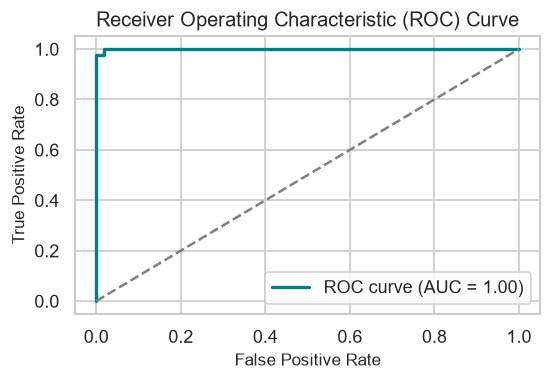

In [13]:
probs = log_reg.predict_proba(X_class)[:, 1]
fpr, tpr, _ = roc_curve(y_class, probs)
roc_auc = auc(fpr, tpr)
print("Computed AUC-ROC Score:", round(roc_auc, 3))

# Visualization
plt.figure(figsize=(5, 3))
plt.plot(fpr, tpr, color='teal', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

The AUC score ranges from $0.0$ to $1.0$:
- $1.0$: A perfect model. It can flawlessly distinguish between the positive and negative classes (100% true positives, 0% false positives).
- $0.5$: Random guessing. The model has no discriminatory power; its performance is equivalent to flipping a coin (represented by the diagonal 45-degree line on the ROC plot).
- $< 0.5$: Worse than random guessing. (This usually means your positive and negative labels are inverted).

General Rule of Thumb for Interpreting AUC:
- $0.90 - 1.0$: Excellent (Outstanding discrimination)
- $0.80 - 0.90$: Good (Acceptable/Excellent)
- $0.70 - 0.80$: Fair (Moderate discrimination)
- $0.60 - 0.70$: Poor (Poor discrimination)
- $0.50 - 0.60$: Fail (No better than random)

## 4. Precision-Recall Curves for Imbalanced Data

### 1. Definition
Precision-Recall (PR) curves plot Precision against Recall across decision thresholds, providing a more reliable evaluation than ROC curves when datasets suffer from severe class imbalance (e.g., 1% fraud rate).

### 2. Math Formula
Area under precision-recall curve ($AUC-PR$) integrates precision $P(r)$ across recall values $r$:
$$\text{AUC-PR} = \int_{0}^{1} P(r) \, dr$$


### 3. Notation Pronunciation
- `Precision-Recall Curve`: "Focuses evaluation on minority positive class performance"
- `Class Imbalance`: "Skewed class distribution where accuracy is misleading"

### 4. Naive Example
Evaluating a fraud detection model on a dataset where 99% of transactions are legitimate and 1% are fraudulent using PR curves.

### 5. Uses
- Imbalanced classification evaluation (fraud, rare diseases, equipment failures).
- Optimizing precision-recall operating points for business constraints.
- Avoiding overly optimistic ROC metrics on skewed data.

In [16]:
precision, recall, _ = precision_recall_curve(y_class, probs)
print("precision : ", precision[:15])
print("recall : ", recall[:15])

precision :  [0.44       0.44444444 0.44897959 0.45360825 0.45833333 0.46315789
 0.46808511 0.47311828 0.47826087 0.48351648 0.48888889 0.49438202
 0.5        0.50574713 0.51162791]
recall :  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


---
## Summary Table

| Evaluation Metric / Curve | Core Formula / Concept | Primary Use Case | Advantage in Analytics |
| :--- | :--- | :--- | :--- |
| **Confusion Matrix** | Cross-tabulation ($TP, FP, TN, FN$) | Detailed error breakdown | Inspecting specific types of classification errors |
| **Precision, Recall, $F_1$** | $\frac{TP}{TP+FP}$ and $\frac{TP}{TP+FN}$ | Binary classification summary | Balancing false positive and false negative trade-offs |
| **AUC-ROC** | Integral of TPR vs FPR | General discrimination ranking | Evaluating model ranking quality across all thresholds |
| **Precision-Recall Curve** | Precision vs Recall trade-off | Imbalanced datasets (fraud/rare events) | More informative than ROC when positive class is rare |